# **Agent parllelisation**

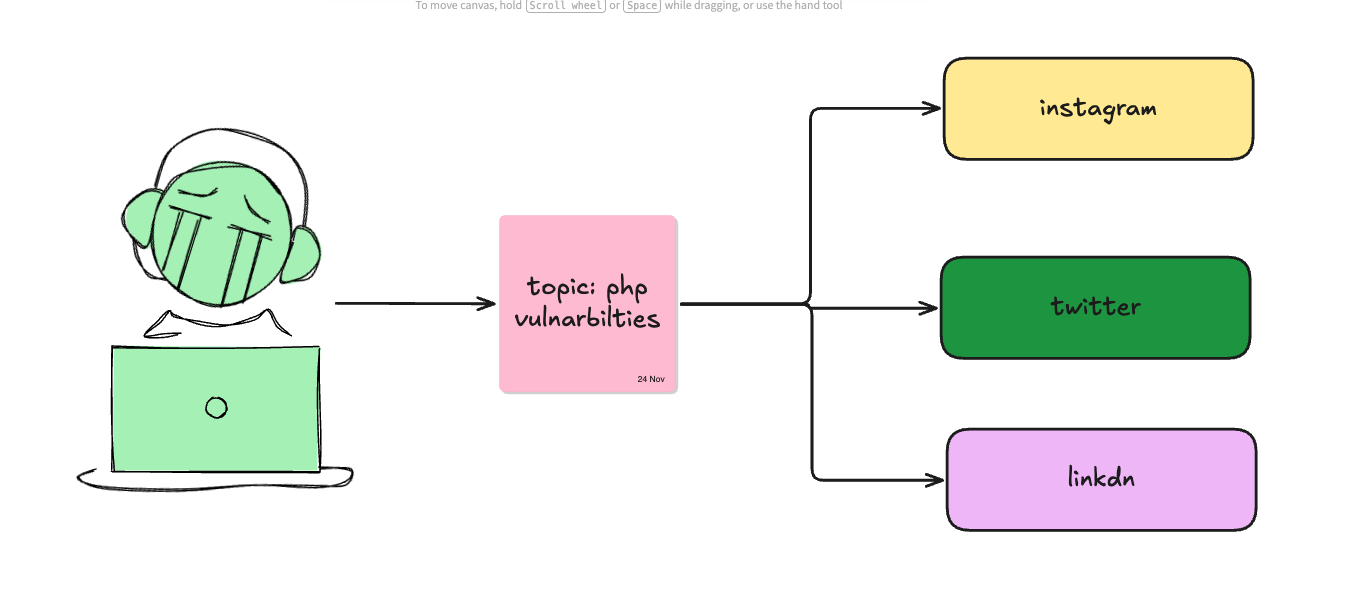

In [1]:
import os
from dotenv import load_dotenv
load_dotenv(override=True)

os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")

In [2]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-4o-mini")

llm.invoke("hi").content

'Hello! How can I assist you today?'

## **Schema**

In [3]:
from typing import TypedDict


class graph_schema(TypedDict):
    topic: str
    insta: str
    twitter: str
    linkedin: str
    
    

# Need Functions

In [4]:
def create_post_insta(state: graph_schema) -> graph_schema:
    

    # Extract the topic from the state
    topic = state['topic']

    # Passing the topic to the LLM to generate an Instagram post
    post = llm.invoke(f"Write an Instagram post about {topic}. Keep the tone in more proffesional and fun way.").content

    # Update the state with the generated post
    state['insta'] = post

    return {'insta' : post}

def create_post_twitter(state: graph_schema) -> graph_schema:
    

    # Extract the topic from the state
    topic = state['topic']

    # Passing the topic to the LLM to generate a Twitter post
    post = llm.invoke(f"Write a Twitter post about {topic}. Keep the tone quick").content

    # Update the state with the generated post
    state['twitter'] = post

    return {'twitter' : post}


def create_post_linkedin(state: graph_schema) -> graph_schema:
    

    # Extract the topic from the state
    topic = state['topic']

    # Passing the topic to the LLM to generate a LinkedIn post
    post = llm.invoke(f"Write a LinkedIn post about {topic}. Keep the tone professional and informative.").content

    # Update the state with the generated post
    state['linkedin'] = post

    return {'linkedin' : post}

In [7]:
from langgraph.graph import StateGraph, START, END

graph = StateGraph(graph_schema)

# Node registartions:

graph.add_node("create_post_insta",create_post_insta)
graph.add_node("create_post_twitter",create_post_twitter)
graph.add_node("create_post_linkedin",create_post_linkedin)

graph.add_edge(START,"create_post_insta")
graph.add_edge(START,"create_post_twitter")
graph.add_edge(START,"create_post_linkedin")


graph.add_edge("create_post_insta",END)
graph.add_edge("create_post_twitter",END)
graph.add_edge("create_post_linkedin",END)


pallel_graph = graph.compile()

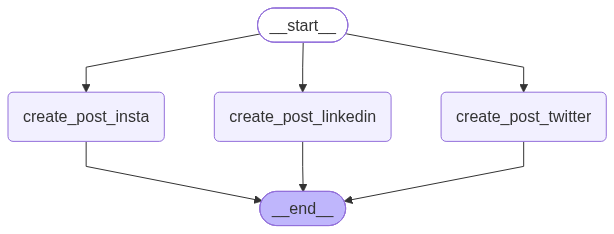

In [8]:
from IPython.display import Image, display
Image(pallel_graph.get_graph().draw_mermaid_png())

In [9]:
pallel_graph.invoke({"topic": "about docker",
                    "insta": "",
                    "twitter": "",
                    "linkedin": ""})

{'topic': 'about docker',
 'insta': '🌊🚀 Dive into the world of Docker! 🎉\n\nDid you know that Docker has revolutionized how we build, ship, and run applications? With its lightweight containers, you can streamline your development workflow and ensure consistency across environments. Whether you’re deploying microservices or managing complex applications, Docker makes it a breeze! \n\n💻✨ Say goodbye to the "It works on my machine" syndrome! With Docker, you can encapsulate your app and its dependencies, guaranteeing that it runs seamlessly in any environment. \n\nHere are a few fun facts to get you excited about Docker:  \n1️⃣ Fast setup – Spin up a container in seconds!  \n2️⃣ Scalability – Scale your applications effortlessly.  \n3️⃣ Portability – Run your containers anywhere, from local machines to cloud services.  \n\nJoin the Docker revolution and elevate your development game! 💪 Have you started using containers yet? Share your experiences below! 👇\n\n#Docker #Containers #DevOps #

# **Router**

Router is nothing but conditional logic 

like i want build only post insta or linkdn or twitter

so we are making our llm to go add change to schema based on request

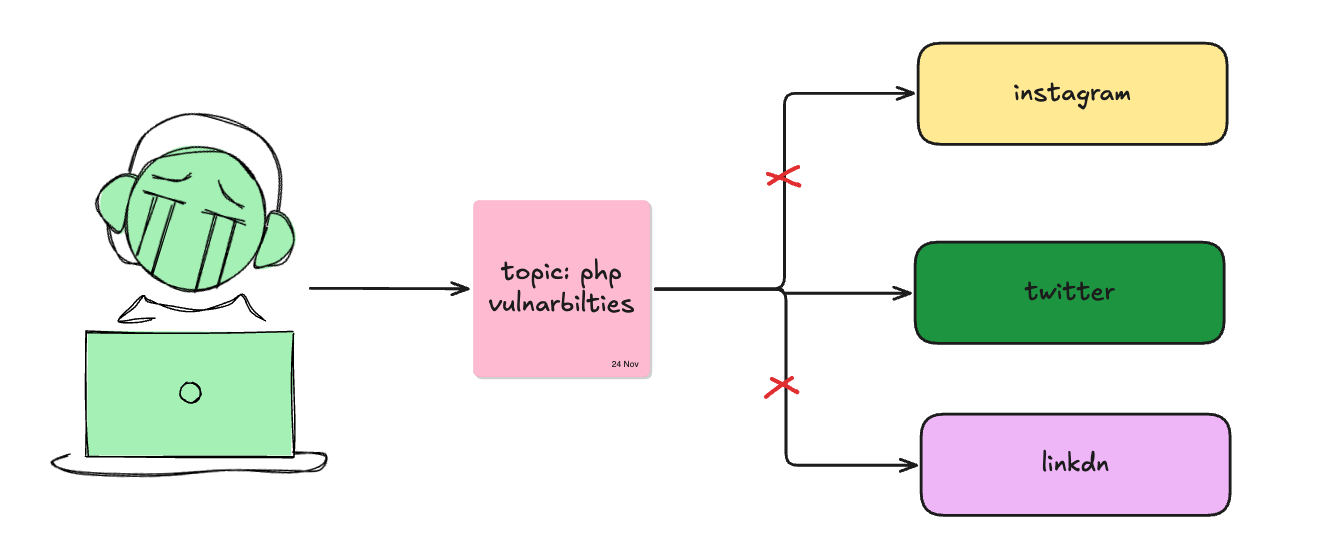

In [10]:
from pydantic import BaseModel, Field
from typing import TypedDict, Literal

class llm_schema(BaseModel):
    category: Literal['insta','linkedin','twitter'] = Field(...,description="category of post to generate")
    topic: str = Field(...,description="topic os the post to generate")

    

In [11]:
llm_with_schema = llm.with_structured_output(llm_schema)

In [12]:
llm_with_schema.invoke("i wanted to generate post on insta").category

'insta'

## State Schema

In [13]:
from typing import TypedDict, List

class graph_schema(TypedDict):
    
    input: str
    topic: str
    post: str
    category: str

In [14]:
def decider_node(state: graph_schema) -> graph_schema:

    # Extract the input from the state
    user_input = state['input']

    # Passing the user input to the LLM to decide the category of the post to generate
    response = llm_with_schema.invoke(user_input) # Pydantic Object
    category = response.category # Extracting the category from the Pydantic Object
    topic = response.topic # Extracting the topic from the Pydantic Object

    # Update the state with the decided category and topic
    state['category'] = category
    state['topic'] = topic

    return state

In [15]:
def create_post_insta(state: graph_schema) -> graph_schema:
    

    # Extract the topic from the state
    topic = state['topic']

    # Passing the topic to the LLM to generate an Instagram post
    post = llm.invoke(f"Write an Instagram post about {topic}. Keep the tone casual and engaging.").content

    # Update the state with the generated post
    state['post'] = post

    return {'post' : post}

def create_post_twitter(state: graph_schema) -> graph_schema:
    

    # Extract the topic from the state
    topic = state['topic']

    # Passing the topic to the LLM to generate a Twitter post
    post = llm.invoke(f"Write a Twitter post about {topic}. Keep the tone quick").content

    # Update the state with the generated post
    state['post'] = post

    return {'post' : post}


def create_post_linkedin(state: graph_schema) -> graph_schema:
    

    # Extract the topic from the state
    topic = state['topic']

    # Passing the topic to the LLM to generate a LinkedIn post
    post = llm.invoke(f"Write a LinkedIn post about {topic}. Keep the tone professional and informative.").content

    # Update the state with the generated post
    state['post'] = post

    return {'post' : post}

In [16]:
def condition(state: graph_schema) -> str:

    category = state['category']

    if category == 'insta':
        return 'create_insta'
    elif category == 'twitter':
        return 'create_twitter'
    elif category == 'linkedin':
        return 'create_linkedin'
    else:
        raise ValueError("Invalid category")

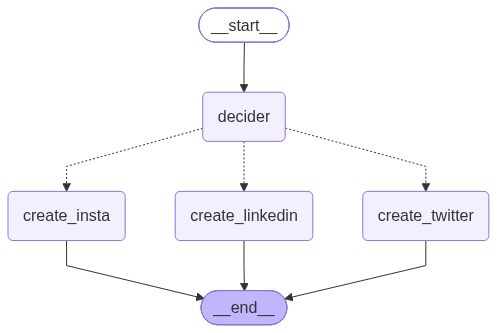

In [17]:
from langgraph.graph import StateGraph, START, END

graph = StateGraph(graph_schema)

graph.add_node("decider", decider_node)
graph.add_node("create_insta", create_post_insta)
graph.add_node("create_twitter", create_post_twitter)
graph.add_node("create_linkedin", create_post_linkedin)


graph.add_edge(START, "decider")
graph.add_conditional_edges("decider",condition,{
    'create_insta': "create_insta",
    'create_twitter': "create_twitter",
    'create_linkedin': "create_linkedin"
})

graph.add_edge("create_insta", END)
graph.add_edge("create_twitter", END)
graph.add_edge("create_linkedin", END) 


route_graph = graph.compile()


from IPython.display import Image, display

# You could see the errors with the below command
Image(route_graph.get_graph().draw_mermaid_png())

In [18]:
route_graph.invoke({
    "input": "I want to generate a post for twitter about AI",
    "topic":"",
    "category":"",
    "post":""
})

{'input': 'I want to generate a post for twitter about AI',
 'topic': 'The impact of AI on the job market',
 'post': '🤖💼 AI is reshaping the job market faster than ever! 🚀 While it’s automating routine tasks, it’s also creating new roles & opportunities. Embrace the change, upskill, and let’s harness the power of AI together! 🌟 #FutureOfWork #AI #JobMarket #Innovation',
 'category': 'twitter'}